In [ ]:
from pathlib import Path

DATA_DIR = Path("../data/chest_xray")
splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

counts = {}
for s in splits:
    for c in classes:
        n = len(list((DATA_DIR / s / c).glob("*.jpeg")))
        counts[(s, c)] = n
        print(f"{s:5s} {c:10s} {n}")

In [1]:
from pathlib import Path

DATA_DIR = Path("../data/chest_xray")
splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

counts = {}
for s in splits:
    for c in classes:
        n = len(list((DATA_DIR / s / c).glob("*.jpeg")))
        counts[(s, c)] = n
        print(f"{s:5s} {c:10s} {n}")

train NORMAL     1341
train PNEUMONIA  3875
val   NORMAL     8
val   PNEUMONIA  8
test  NORMAL     234
test  PNEUMONIA  390


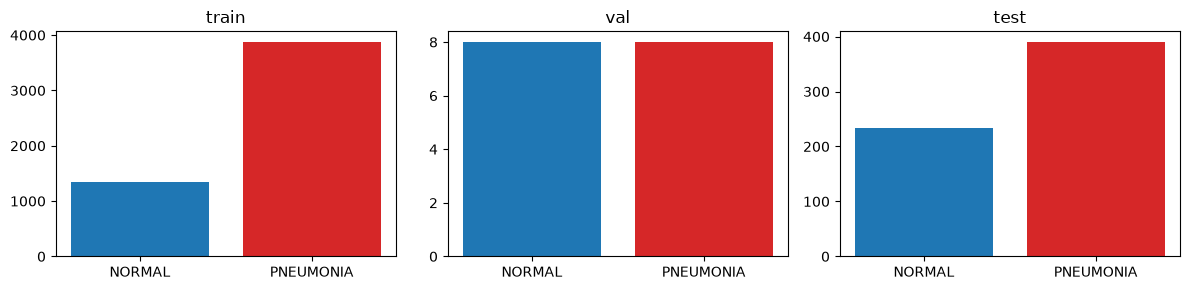

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, s in zip(axes, splits):
    ax.bar(classes, [counts[(s, c)] for c in classes], color=["tab:blue", "tab:red"])
    ax.set_title(s)
plt.tight_layout()
plt.savefig("../results/class_distribution.png", dpi=150)
plt.show()

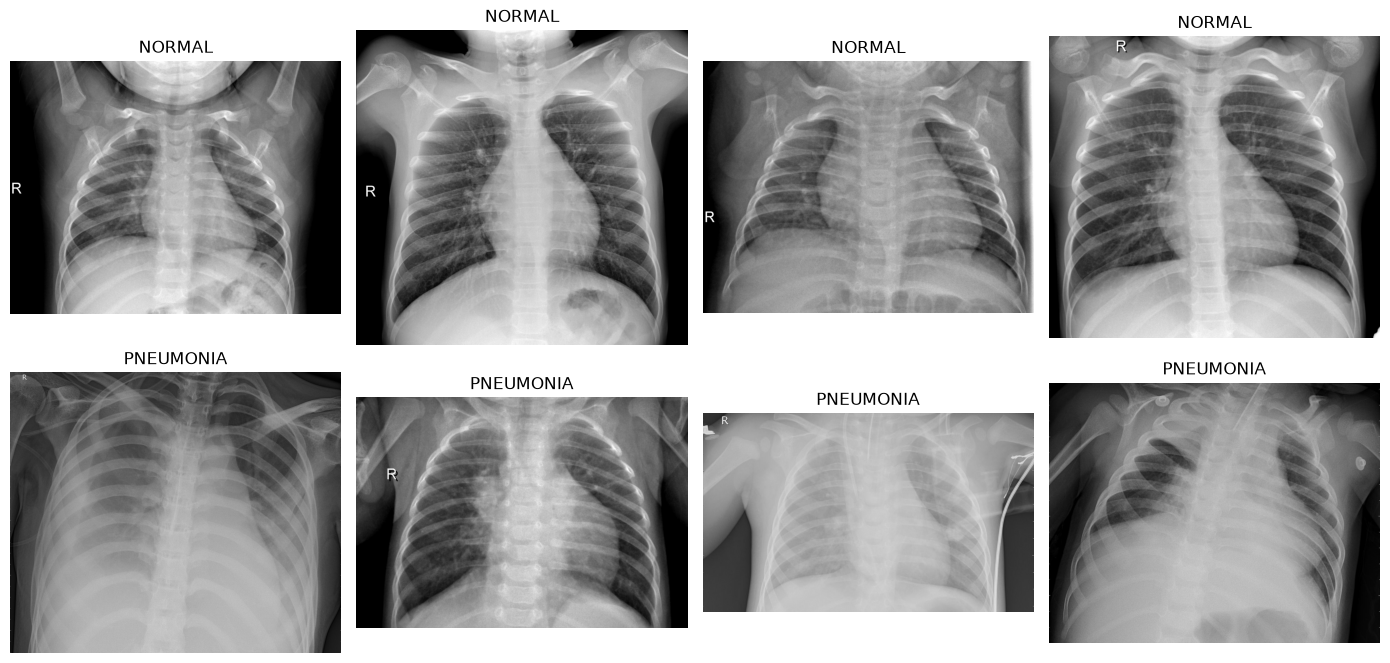

In [3]:
from PIL import Image
import random

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, c in enumerate(classes):
    files = random.sample(list((DATA_DIR / "train" / c).glob("*.jpeg")), 4)
    for col, f in enumerate(files):
        axes[row, col].imshow(Image.open(f).convert("L"), cmap="gray")
        axes[row, col].set_title(c)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("../results/sample_images.png", dpi=150)
plt.show()

In [4]:
sizes = [Image.open(f).size for f in random.sample(list((DATA_DIR / "train" / "NORMAL").glob("*.jpeg")), 100)]
widths, heights = zip(*sizes)
print("Width range:", min(widths), "-", max(widths))
print("Height range:", min(heights), "-", max(heights))

Width range: 1090 - 2428
Height range: 793 - 2540
